In [58]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

og_data  = pd.read_csv("original_data.csv").values
imp_data = pd.read_csv("masked_data.csv").values

def pca_imputation(data, rank):
    
    # Step 1: Replace missing values with column mean
    data_imputed = data.copy()
    col_means = np.nanmean(data_imputed, axis=0)
    inds = np.where(np.isnan(data_imputed))
    data_imputed[inds] = np.take(col_means, inds[1])

    # Step 2: Perform SVD
    U, S, Vt = np.linalg.svd(data_imputed, full_matrices=False)

    # Step 3: Truncate SVD matrices for low-rank approximation
    Ud = U[:, :rank]
    Sd = np.diag(S[:rank])
    Vd = Vt[:rank, :]

    # Step 4: Reconstruct the dataset using low-rank approximation
    X_approx = np.dot(Ud, np.dot(Sd, Vd))

    return X_approx


In [43]:
def compute_mse(original_data, imputed_data):
    mask = ~np.isnan(original_data)
    mse = np.mean((original_data[mask] - imputed_data[mask])**2)
    return mse


In [69]:
rank = 2

pca_og_data = pca_imputation(og_data, rank)
pca_imp_data = pca_imputation(imp_data, rank)


# Compute MSE for PCA
mse_pca = compute_mse(pca_og_data, pca_imp_data)


print("MSE for PCA Imputation:", mse_pca)


MSE for PCA Imputation: 0.35621345536507326


In [70]:
def ppca_imputation(data, rank, max_iter=100, tol=1e-4):
    # Step 1: Replace missing values with column mean for initialization
    data_imputed = data.copy()
    col_means = np.nanmean(data_imputed, axis=0)
    inds = np.where(np.isnan(data_imputed))
    data_imputed[inds] = np.take(col_means, inds[1])

    n, d = data_imputed.shape
    W = np.random.randn(d, rank)  # Initialize loading matrix
    sigma_sq = 1.0  # Initialize variance of noise

    for iteration in range(max_iter):
        # E-step: Compute the expected values of the latent variables
        M = W.T @ W + sigma_sq * np.eye(rank)
        M_inv = np.linalg.inv(M)
        Ez = M_inv @ W.T @ data_imputed.T
        EzzT = sigma_sq * M_inv + Ez @ Ez.T / n

        # M-step: Update W and sigma_sq with regularization
        EzzT_reg = EzzT + 1e-6 * np.eye(rank)  # Add regularization to EzzT
        W_new = data_imputed.T @ Ez.T @ np.linalg.inv(EzzT_reg)
        residual = data_imputed - (Ez.T @ W_new.T)
        sigma_sq_new = np.sum(residual**2) / (n * d)

        # Check for convergence
        if np.linalg.norm(W_new - W) < tol and abs(sigma_sq_new - sigma_sq) < tol:
            break

        W = W_new
        sigma_sq = sigma_sq_new

    # Impute missing values using the final model
    X_imputed = (Ez.T @ W.T).T
    data_imputed[inds] = X_imputed[inds]

    return data_imputed


# Perform PPCA-based imputation
ppca_og_data = ppca_imputation(og_data, rank)
ppca_imp_data = ppca_imputation(imp_data, rank)

# Compute MSE for PCA and PPCA
mse_ppca = compute_mse(ppca_og_data, ppca_imp_data)

print("MSE for PPCA Imputation:", mse_ppca)

IndexError: index 20 is out of bounds for axis 0 with size 20

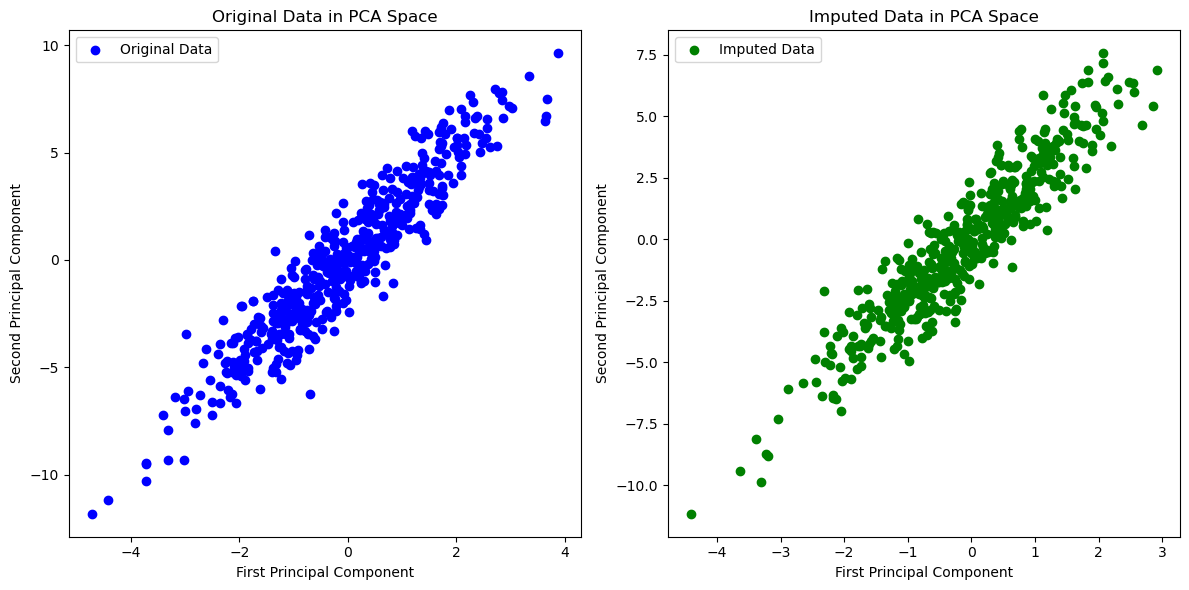

In [71]:
# Create scatter plots
fig, axs = plt.subplots(1, 2, figsize=(12, 6))

# Plot for original data
axs[0].scatter(pca_og_data[:, 0], pca_og_data[:, 1], color='blue', label='Original Data')
axs[0].set_title('Original Data in PCA Space')
axs[0].set_xlabel('First Principal Component')
axs[0].set_ylabel('Second Principal Component')
axs[0].legend()

# Plot for imputed data
axs[1].scatter(pca_imp_data[:, 0], pca_imp_data[:, 1], color='green', label='Imputed Data')
axs[1].set_title('Imputed Data in PCA Space')
axs[1].set_xlabel('First Principal Component')
axs[1].set_ylabel('Second Principal Component')
axs[1].legend()

plt.tight_layout()
plt.show()

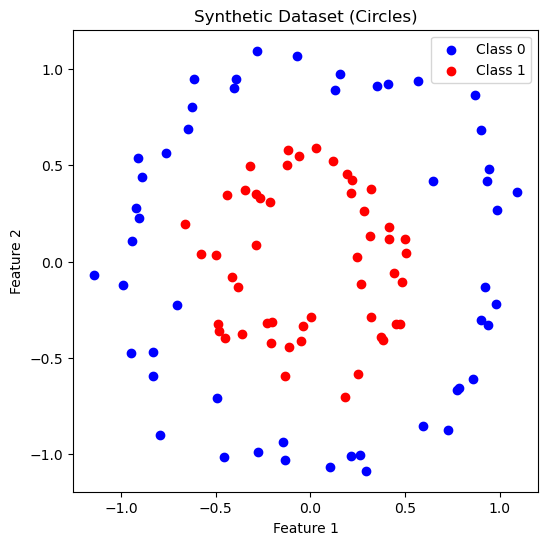

In [72]:
import matplotlib.pyplot as plt
from sklearn.datasets import make_circles

# Generate synthetic data with a non-linear structure (circles)
X, y = make_circles(n_samples=100, noise=0.1, factor=0.5)

# Visualize the dataset
plt.figure(figsize=(6, 6))
plt.scatter(X[y == 0, 0], X[y == 0, 1], color='blue', label='Class 0')
plt.scatter(X[y == 1, 0], X[y == 1, 1], color='red', label='Class 1')
plt.title("Synthetic Dataset (Circles)")
plt.xlabel('Feature 1')
plt.ylabel('Feature 2')
plt.legend()
plt.show()


In [73]:

from sklearn.preprocessing import StandardScaler
def rbf_kernel(X, sigma=1.0):
    """Compute the RBF kernel between all pairs of points in X."""
    pairwise_sq_dists = np.sum(X**2, axis=1).reshape(-1, 1) + np.sum(X**2, axis=1) - 2 * np.dot(X, X.T)
    return np.exp(-pairwise_sq_dists / (2 * sigma ** 2))

def center_kernel_matrix(K):
    """Center the kernel matrix K."""
    N = K.shape[0]
    H = np.eye(N) - np.ones((N, N)) / N
    return np.dot(np.dot(H, K), H)

def kernel_pca(X, sigma=1.0, n_components=2):
    """Perform Kernel PCA with RBF kernel."""
    # Compute the RBF kernel matrix
    K = rbf_kernel(X, sigma)
    
    # Center the kernel matrix
    K_centered = center_kernel_matrix(K)
    
    # Eigenvalue decomposition
    eigenvalues, eigenvectors = np.linalg.eigh(K_centered)
    
    # Sort eigenvalues and eigenvectors
    sorted_indices = np.argsort(eigenvalues)[::-1]
    eigenvalues = eigenvalues[sorted_indices]
    eigenvectors = eigenvectors[:, sorted_indices]
    
    # Select the top n_components eigenvectors
    selected_eigenvectors = eigenvectors[:, :n_components]
    
    # Project the data into the new space
    projections = np.dot(K_centered, selected_eigenvectors)
    
    return projections, eigenvalues, eigenvectors



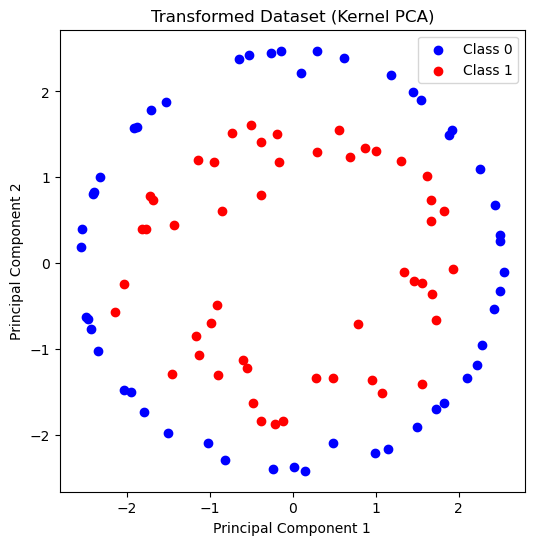

In [74]:
# Apply Kernel PCA on the dataset
X_projected, eigenvalues, eigenvectors = kernel_pca(X, sigma=1.0, n_components=2)

# Visualize the transformed dataset in the reduced 2D space
plt.figure(figsize=(6, 6))
plt.scatter(X_projected[y == 0, 0], X_projected[y == 0, 1], color='blue', label='Class 0')
plt.scatter(X_projected[y == 1, 0], X_projected[y == 1, 1], color='red', label='Class 1')
plt.title("Transformed Dataset (Kernel PCA)")
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.legend()
plt.show()
